<img src="https://www.institutomillenium.org.br/wp-content/uploads/2024/02/logo-ibmec-topo-rj-450x150.png.webp" width=300>

# Programação para Análise de Dados

## Aula 1 — Correlação e Regressão Linear (Simples e Múltipla)

**Duração:** 1h50 · **Bibliotecas:** `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`

| Bloco | Tema | Tempo |
|---|---|---|
| 1 | Preparação do ambiente | 5 min |
| 2 | Dados sintéticos: horas de estudo × nota | 10 min |
| 3 | Correlação | 15 min |
| 4 | Regressão linear simples, passo a passo | 30 min |
| 5 | Regressão linear múltipla | 20 min |
| 6 | Dataset real do scikit-learn: Diabetes | 20 min |
| 7 | Exercícios e fechamento | 10 min |

> **Como usar este notebook:** antes de cada bloco de código há uma explicação em texto e, logo abaixo, a lista **"Linha a linha"**. Dentro do código, cada linha também tem um comentário `# ...`. Execute as células **em ordem**, com `Shift + Enter`.

# 🧰 Bloco 1 — Preparação do ambiente (5 min)

Todo programa em Python começa **importando bibliotecas**: conjuntos de ferramentas já prontas. Importamos uma vez, no início.

### Importando as bibliotecas

Rode a célula abaixo. Se aparecer "Ambiente pronto!", está tudo certo.

**🔍 Linha a linha**

- `import numpy as np`: carrega o numpy e dá a ele o apelido `np` (para digitar menos).
- `import pandas as pd`: carrega o pandas (tabelas), apelido `pd`.
- `import matplotlib.pyplot as plt` e `import seaborn as sns`: carregam as bibliotecas de gráficos.
- `from sklearn... import ...`: traz do scikit-learn **só** o que vamos usar: o modelo (`LinearRegression`), a divisão treino/teste e as métricas.
- `warnings.filterwarnings('ignore')`: esconde avisos amarelos que não atrapalham.
- `sns.set_theme(...)` e `plt.rcParams[...]`: definem o estilo e o tamanho dos gráficos.
- `AZUL, OURO, VERM, CINZA = ...`: guarda quatro cores em variáveis para reutilizar nos gráficos.

In [1]:
import numpy as np                                    # numpy: contas com números e sorteios aleatórios
import pandas as pd                                   # pandas: tabelas de dados (DataFrame)
import matplotlib.pyplot as plt                       # matplotlib: gráficos
import seaborn as sns                                 # seaborn: gráficos estatísticos (usaremos o heatmap)
from sklearn.linear_model import LinearRegression     # o modelo de regressão linear
from sklearn.model_selection import train_test_split  # separa os dados em treino e teste
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error  # métricas de qualidade
import warnings                                       # avisos do Python
warnings.filterwarnings('ignore')                     # esconde avisos para a saída ficar limpa

sns.set_theme(style='whitegrid')                      # estilo visual dos gráficos: fundo claro com grade
plt.rcParams['figure.figsize'] = (7, 4.5)             # tamanho padrão dos gráficos (largura, altura)

AZUL, OURO, VERM, CINZA = '#16273E', '#F4AC02', '#C0392B', '#8C8C8C'   # cores que usaremos
print('Ambiente pronto!')                             # mensagem de confirmação

Ambiente pronto!


# 🧪 Bloco 2 — Dados sintéticos (10 min)

**Dados sintéticos** são dados que **nós mesmos criamos**. A vantagem: sabemos a "regra verdadeira" por trás deles e podemos conferir se a regressão a descobre.

Nosso exemplo: **horas de estudo → nota na prova**. Vamos dizer que a regra verdadeira é:

$$nota = 30 + 6 \times horas + erro$$

Ou seja, quem não estuda tira cerca de 30 e cada hora de estudo soma cerca de 6 pontos. O **erro** é a parte aleatória da vida (sono, sorte, nervosismo...).

### Criando os dados

Criamos 50 alunos fictícios e guardamos tudo em uma tabela (DataFrame).

**🔍 Linha a linha**

- `rng = np.random.default_rng(42)`: cria o "sorteador". O número 42 é a **semente**: com a mesma semente, o sorteio é sempre o mesmo.
- `horas = rng.uniform(0, 10, n)`: sorteia `n` números **uniformes** (qualquer valor entre 0 e 10 é igualmente provável).
- `erro = rng.normal(0, 5, n)`: sorteia `n` erros em forma de sino (**normal**): a maioria perto de 0, poucos longe.
- `nota = 30 + 6 * horas + erro`: aplica a fórmula. O numpy faz a conta para os 50 alunos de uma vez.
- `.clip(0, 100)`: corta valores abaixo de 0 ou acima de 100.
- `pd.DataFrame({...})`: transforma as listas em uma tabela; as chaves (`'horas_estudo'`, `'nota'`) viram os nomes das colunas.
- `.round(1)`: arredonda para 1 casa decimal. `.head()` mostra o começo da tabela.

In [2]:
rng = np.random.default_rng(42)                 # cria o gerador de números aleatórios; 42 é a "semente" (todos obtêm os mesmos números)
n = 50                                          # número de alunos
horas = rng.uniform(0, 10, n)                   # sorteia 50 valores entre 0 e 10 horas de estudo
erro = rng.normal(0, 5, n)                      # sorteia 50 "erros" (média 0 e desvio-padrão 5)
nota = 30 + 6 * horas + erro                    # aplica a regra verdadeira: nota = 30 + 6 x horas + erro
nota = nota.clip(0, 100)                        # garante que a nota fique entre 0 e 100

df_notas = pd.DataFrame({                       # monta a tabela com duas colunas
    'horas_estudo': horas.round(1),             # coluna 1: horas, com 1 casa decimal
    'nota': nota.round(1)                       # coluna 2: nota, com 1 casa decimal
})
df_notas.head()                                 # mostra as 5 primeiras linhas da tabela

,horas_estudo,nota
0,7.7,79.8
1,4.4,56.7
2,8.6,83.0
3,7.0,75.0
4,0.9,28.4


### Olhando os dados: gráfico de dispersão

Antes de qualquer conta, **sempre desenhe os dados**. Cada ponto é um aluno.

**🔍 Linha a linha**

- `plt.scatter(x, y)`: gráfico de **dispersão**; recebe a coluna do eixo x e a do eixo y.
- `df_notas['horas_estudo']`: pega uma coluna da tabela pelo nome.
- `color=AZUL, label=...`: cor dos pontos e o texto que aparecerá na legenda.
- `plt.title`, `plt.xlabel`, `plt.ylabel`: título e nomes dos eixos (todo gráfico deve ter!).
- `plt.legend()` desenha a legenda; `plt.show()` mostra o gráfico.

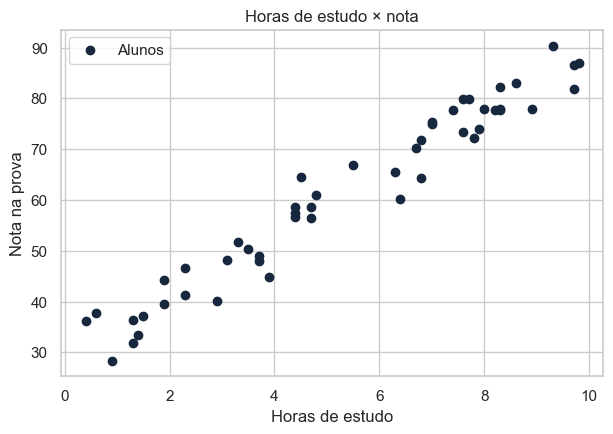

In [3]:
plt.scatter(df_notas['horas_estudo'], df_notas['nota'],   # desenha pontos: x = horas, y = nota
            color=AZUL, label='Alunos')                   # cor azul e nome para a legenda
plt.title('Horas de estudo × nota')                       # título do gráfico
plt.xlabel('Horas de estudo')                             # nome do eixo horizontal
plt.ylabel('Nota na prova')                               # nome do eixo vertical
plt.legend()                                              # mostra a legenda
plt.show()                                                # exibe o gráfico

👀 **O que vemos:** os pontos formam uma "nuvem" inclinada para cima: quanto mais horas, maior a nota. É uma relação **positiva** e aproximadamente **em linha reta**.

# 🔗 Bloco 3 — Correlação (15 min)

> **Analogia:** duas pessoas dançando. Se uma dá um passo à frente e a outra também, elas se movem **juntas** (correlação positiva). Se uma avança e a outra recua, é correlação **negativa**. Se cada uma dança uma música diferente, **não há correlação**.

A **correlação de Pearson** (símbolo **r**) mede a força dessa "dança" **em linha reta**. Ela vai de **−1 a +1**:

| r | Leitura |
|---|---|
| perto de **+1** | sobem juntas (forte, positiva) |
| perto de **0** | sem relação em linha reta |
| perto de **−1** | uma sobe, a outra desce (forte, negativa) |

Regra de bolso: |r| < 0,3 fraca · entre 0,3 e 0,7 moderada · acima de 0,7 forte.

> ⚠️ **Correlação não é causalidade.** Sorvete e afogamentos sobem juntos no verão, mas um não causa o outro (o calor causa ambos).

### Calculando a correlação

O pandas calcula r com uma linha.

**🔍 Linha a linha**

- `coluna_a.corr(coluna_b)`: calcula o r entre duas colunas.
- `f'Correlação r = {r:.2f}'`: texto em que `{r:.2f}` é substituído pelo valor de r com 2 casas decimais.
- `df_notas.corr()`: gera a **matriz de correlação** (todas as colunas contra todas). A diagonal é sempre 1 (cada coluna é igual a ela mesma).
- `.round(2)`: arredonda a tabela para 2 casas.

In [4]:
r = df_notas['horas_estudo'].corr(df_notas['nota'])   # correlação entre as duas colunas
print(f'Correlação r = {r:.2f}')                      # mostra r com 2 casas decimais
print()                                               # linha em branco
print(df_notas.corr().round(2))                       # tabela de correlações entre todas as colunas

Correlação r = 0.98

              horas_estudo  nota
horas_estudo          1.00  0.98
nota                  0.98  1.00


### Heatmap: a matriz de correlação em cores

Com muitas variáveis, a tabela de números fica difícil de ler. O **heatmap** (mapa de calor) pinta cada célula de acordo com o valor de r. Vamos usá-lo adiante, com mais variáveis. Aqui vai um primeiro exemplo:

### Heatmap simples

Vermelho = correlação positiva forte; azul = negativa; branco = perto de zero.

**🔍 Linha a linha**

- `corr = df_notas.corr()`: guarda a matriz de correlação em uma variável.
- `sns.heatmap(corr, ...)`: desenha a matriz como mapa de cores.
- `annot=True, fmt='.2f'`: escreve os valores nas células, com 2 casas decimais.
- `cmap='coolwarm', vmin=-1, vmax=1`: azul para valores negativos, vermelho para positivos; fixar de −1 a 1 mantém a leitura igual em todos os gráficos.
- `cbar_kws={'label': ...}`: legenda da barra de cores.

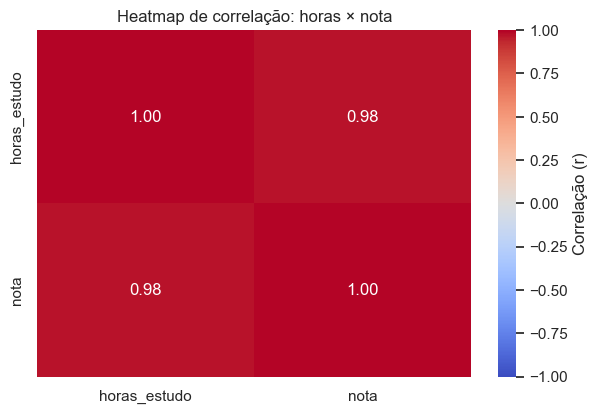

In [5]:
corr = df_notas.corr()                                  # matriz de correlação
sns.heatmap(corr, annot=True, fmt='.2f',                # annot=True escreve o número em cada célula
            cmap='coolwarm', vmin=-1, vmax=1,           # paleta azul-vermelho, escala fixa de -1 a 1
            cbar_kws={'label': 'Correlação (r)'})       # título da barra de cores
plt.title('Heatmap de correlação: horas × nota')        # título do gráfico
plt.show()                                              # exibe

# 📈 Bloco 4 — Regressão linear simples, passo a passo (30 min)

A correlação diz **o quanto** duas variáveis andam juntas. A **regressão** vai além: desenha a **reta** que melhor descreve a relação e permite **prever**.

$$\hat{y} = b_0 + b_1 \cdot x$$

- **x** = variável explicativa (aqui, horas de estudo).
- **ŷ** ("y chapéu") = valor previsto (aqui, nota prevista).
- **b₁ (coeficiente)** = inclinação: quanto a nota **muda, em média, a cada +1 hora**.
- **b₀ (intercepto)** = onde a reta cruza o eixo: nota prevista para **0 hora**.

> **Como a reta é escolhida?** Para cada aluno há um **erro** (nota real − nota prevista). A reta escolhida é a que deixa a **soma dos erros ao quadrado a menor possível** (método dos *mínimos quadrados*). É a reta que passa "no meio" da nuvem.

> **Treino e teste (a prova surpresa):** separamos os dados em duas partes. O modelo **estuda** na parte de **treino** e é **avaliado** na parte de **teste**, que ele nunca viu. É como dar uma prova com questões inéditas: mostra se aprendeu ou só decorou.

### Os 7 passos
| Passo | O que fazer |
|---|---|
| 1 | Separar **X** (explicativa) e **y** (o que queremos prever) |
| 2 | Dividir em treino e teste |
| 3 | Criar o modelo |
| 4 | Treinar (`fit`) |
| 5 | Ver os coeficientes |
| 6 | Prever (`predict`) |
| 7 | Avaliar (R², MAE, RMSE) |

### Passos 1 e 2 — Separar X e y, e dividir treino e teste

X vai com **colchetes duplos** (é uma tabela); y com colchetes simples (é uma coluna só).

**🔍 Linha a linha**

- `X = df_notas[['horas_estudo']]`: **dois colchetes** produzem uma tabela de 1 coluna. O scikit-learn exige X em formato de tabela.
- `y = df_notas['nota']`: **um colchete** produz uma coluna só.
- `train_test_split(X, y, ...)`: embaralha e separa. Devolve **quatro** pedaços, nesta ordem: X de treino, X de teste, y de treino, y de teste.
- `test_size=0.2`: 20% dos alunos ficam reservados para o teste.
- `random_state=42`: fixa o embaralhamento para o resultado ser repetível.
- `len(...)`: conta quantas linhas há.

In [6]:
X = df_notas[['horas_estudo']]                          # passo 1: X = coluna(s) explicativa(s), em formato de tabela
y = df_notas['nota']                                    # passo 1: y = o que queremos prever

X_treino, X_teste, y_treino, y_teste = train_test_split(   # passo 2: divide em 4 partes
    X, y,                                               # os dados a dividir
    test_size=0.2,                                      # 20% vão para o teste e 80% para o treino
    random_state=42)                                    # semente: a divisão é sempre a mesma

print('Alunos no treino:', len(X_treino))               # quantos alunos para estudar
print('Alunos no teste :', len(X_teste))                # quantos alunos para a "prova"

Alunos no treino: 40
Alunos no teste : 10


### Passos 3 e 4 — Criar e treinar o modelo

"Criar" é pegar o modelo vazio; `fit` é o momento em que ele **aprende** a reta olhando os dados de treino.

**🔍 Linha a linha**

- `LinearRegression()`: cria o modelo de regressão linear e o guarda em `modelo_simples`.
- `.fit(X_treino, y_treino)`: "ajuste" ou treino. O modelo descobre os melhores valores de b₀ e b₁ usando só o **treino**.

In [7]:
modelo_simples = LinearRegression()                     # passo 3: cria o modelo (ainda vazio, não aprendeu nada)
modelo_simples.fit(X_treino, y_treino)                  # passo 4: treina; ele calcula a melhor reta para o treino
print('Modelo treinado!')                               # confirmação

Modelo treinado!


### Passo 5 — Ver os coeficientes

Aqui está a "fórmula" que o modelo encontrou. Compare com a regra verdadeira (30 e 6).

**🔍 Linha a linha**

- `modelo_simples.intercept_`: o intercepto b₀ (o sublinhado final é padrão do scikit-learn para valores aprendidos).
- `modelo_simples.coef_`: lista de coeficientes (um por variável). Como há uma só variável, pegamos o primeiro com `[0]`.
- Os valores ficaram próximos de 30 e 6: o modelo **recuperou** a regra verdadeira, mesmo com o erro aleatório!

In [8]:
b0 = modelo_simples.intercept_                          # intercepto (b0) encontrado
b1 = modelo_simples.coef_[0]                            # coeficiente (b1) da única variável
print(f'Intercepto (b0): {b0:.2f}')                     # nota prevista para 0 hora
print(f'Coeficiente (b1): {b1:.2f}')                    # pontos ganhos por hora extra
print(f'Equação: nota = {b0:.1f} + {b1:.1f} x horas')   # equação completa

Intercepto (b0): 27.89
Coeficiente (b1): 6.19
Equação: nota = 27.9 + 6.2 x horas


### Passo 6 — Prever

Com o modelo treinado, usamos `predict` nas horas do **teste** e comparamos com as notas reais.

**🔍 Linha a linha**

- `modelo_simples.predict(X_teste)`: aplica a reta a cada linha de `X_teste` e devolve as notas previstas.
- `.values`: extrai só os valores (sem o índice) para montar a nova tabela sem confusão.
- `comparacao['erro'] = ...`: cria uma nova coluna: **erro = real − previsto**. Positivo = o modelo previu menos do que o real.

In [9]:
y_prev = modelo_simples.predict(X_teste)                # passo 6: nota prevista para cada aluno do teste

comparacao = pd.DataFrame({                             # tabela para comparar real e previsto
    'horas': X_teste['horas_estudo'].values,            # horas de cada aluno do teste
    'nota_real': y_teste.values,                        # nota que o aluno realmente tirou
    'nota_prevista': y_prev.round(1)                    # nota que o modelo previu
})
comparacao['erro'] = (comparacao['nota_real'] - comparacao['nota_prevista']).round(1)   # erro = real - previsto
comparacao.head(6)                                      # mostra 6 linhas

,horas,nota_real,nota_prevista,erro
0,8.2,77.7,78.7,-1.0
1,6.7,70.3,69.4,0.9
2,7.4,77.8,73.7,4.1
3,8.0,77.9,77.4,0.5
4,0.6,37.8,31.6,6.2
5,6.8,64.3,70.0,-5.7


### Visualizando a reta

A reta deve passar "no meio" da nuvem de pontos.

**🔍 Linha a linha**

- As duas primeiras linhas desenham os pontos de treino (azul) e de teste (dourado).
- `x_linha`: uma reta precisa de só **dois pontos**; usamos 0 e 10 horas.
- `modelo_simples.predict(x_linha)`: calcula a nota prevista nesses dois pontos.
- `plt.plot(x, y)`: liga os pontos com uma **linha** (diferente do `scatter`, que só desenha pontos).

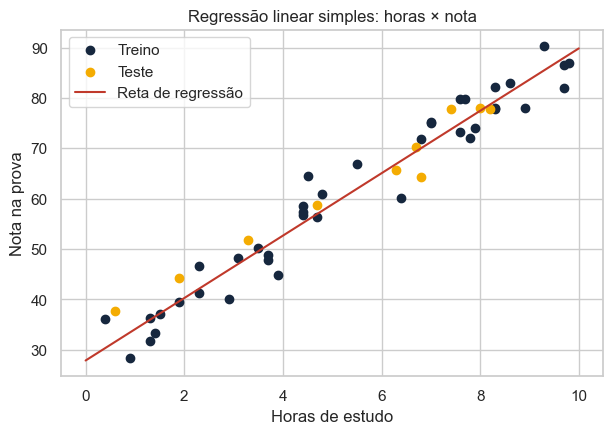

In [10]:
plt.scatter(X_treino['horas_estudo'], y_treino, color=AZUL, label='Treino')       # pontos de treino
plt.scatter(X_teste['horas_estudo'], y_teste, color=OURO, label='Teste')          # pontos de teste

x_linha = pd.DataFrame({'horas_estudo': [0, 10]})        # dois pontos extremos para desenhar a reta
y_linha = modelo_simples.predict(x_linha)                # nota prevista nesses dois pontos
plt.plot(x_linha['horas_estudo'], y_linha, color=VERM, label='Reta de regressão')   # liga os dois pontos

plt.title('Regressão linear simples: horas × nota')      # título
plt.xlabel('Horas de estudo')                            # eixo x
plt.ylabel('Nota na prova')                              # eixo y
plt.legend()                                             # legenda
plt.show()                                               # exibe

### Passo 7 — Avaliar o modelo

Três métricas simples, sempre calculadas **no teste**.

**🔍 Linha a linha**

- `r2_score(y_real, y_previsto)`: calcula o **R²**.
- `mean_absolute_error(...)`: calcula o **MAE**, a média dos erros em valor absoluto (ignora o sinal).
- `mean_squared_error(...)`: média dos erros ao quadrado; `np.sqrt(...)` tira a raiz e volta à unidade original, resultando no **RMSE**.

In [11]:
r2 = r2_score(y_teste, y_prev)                          # R²: parte da variação das notas explicada pelo modelo
mae = mean_absolute_error(y_teste, y_prev)              # MAE: erro médio, em pontos de nota
rmse = np.sqrt(mean_squared_error(y_teste, y_prev))     # RMSE: erro "médio" que pune erros grandes

print(f'R²  = {r2:.3f}')                                # de 0 a 1 (quanto maior, melhor)
print(f'MAE = {mae:.2f} pontos')                        # quanto o modelo erra, em média
print(f'RMSE = {rmse:.2f} pontos')                      # similar ao MAE, mas pune mais os erros grandes

R²  = 0.931
MAE = 2.94 pontos
RMSE = 3.56 pontos


### 📏 Como ler as métricas

| Métrica | Significa | Leitura |
|---|---|---|
| **R²** | Proporção da variação do alvo explicada pelo modelo | 0 = não explica nada · 1 = explica tudo. Ex.: R² = 0,90 → o modelo explica 90% da variação das notas |
| **MAE** | Erro médio absoluto | Está na **mesma unidade** do alvo. MAE = 4 → erra, em média, 4 pontos |
| **RMSE** | Raiz do erro quadrático médio | Também na unidade do alvo; **maior que o MAE** quando há erros grandes isolados |

> **Dica:** quanto **menores** MAE e RMSE e **maior** o R², melhor. Compare sempre no **teste**.

### Usando o modelo: prever para um aluno novo

Qual nota esperar de quem estuda 7,5 horas?

**🔍 Linha a linha**

- `pd.DataFrame({'horas_estudo': [7.5]})`: o novo caso precisa ter o **mesmo formato e o mesmo nome de coluna** do treino.
- `nota_prevista[0]`: `predict` devolve uma lista; `[0]` pega o primeiro valor.

In [12]:
novo_aluno = pd.DataFrame({'horas_estudo': [7.5]})      # tabela com 1 aluno novo (mesmo nome de coluna do treino)
nota_prevista = modelo_simples.predict(novo_aluno)      # previsão do modelo
print(f'Nota prevista para 7,5 horas: {nota_prevista[0]:.1f}')   # [0] pega o primeiro (e único) resultado

Nota prevista para 7,5 horas: 74.3


# 🎯 Exercício 1 (5 min) — Prever

**Desafio:** use o `modelo_simples` para prever a nota de um aluno que estuda **8 horas**. Mostre o resultado com 1 casa decimal.

In [13]:
# TODO: crie uma tabela com 'horas_estudo' = 8 e use modelo_simples.predict(...)

# 🏠 Bloco 5 — Regressão linear múltipla (20 min)

Na vida real, um resultado raramente depende de **uma só** variável. O preço de um imóvel depende da área, da idade, da distância do centro...

A **regressão múltipla** usa várias variáveis ao mesmo tempo:

$$\hat{y} = b_0 + b_1 x_1 + b_2 x_2 + b_3 x_3$$

Cada variável ganha seu **próprio coeficiente**, interpretado assim:

> **"Mantendo as outras variáveis constantes"**: o coeficiente da área diz quanto o preço muda quando só a área aumenta 1 m², com idade e distância iguais.

Os passos são **os mesmos** do Bloco 4; só muda o X (agora com várias colunas).

Dados sintéticos (preço em **R$ mil**), regra verdadeira:

$$preço = 100 + 5 \cdot área - 3 \cdot idade - 8 \cdot distância + erro$$

### Criando os dados dos imóveis

Mesma ideia do Bloco 2, agora com três variáveis explicativas.

**🔍 Linha a linha**

- Mesma sequência do Bloco 2: sortear as variáveis, sortear o erro, aplicar a fórmula e montar a tabela.
- Sinais da regra: **área** soma (+5 por m²); **idade** e **distância** subtraem (−3 e −8).

In [14]:
rng = np.random.default_rng(7)                          # novo gerador, semente 7
n = 200                                                 # 200 imóveis
area = rng.uniform(40, 200, n)                          # área entre 40 e 200 m²
idade = rng.uniform(0, 40, n)                           # idade do imóvel entre 0 e 40 anos
distancia = rng.uniform(1, 20, n)                       # distância do centro entre 1 e 20 km
erro = rng.normal(0, 50, n)                             # parte aleatória (desvio 50 mil)
preco = 100 + 5 * area - 3 * idade - 8 * distancia + erro   # regra verdadeira

df_imoveis = pd.DataFrame({                             # monta a tabela
    'area_m2': area.round(1),
    'idade_anos': idade.round(1),
    'distancia_km': distancia.round(1),
    'preco_mil': preco.round(1)
})
df_imoveis.head()                                       # mostra o começo

,area_m2,idade_anos,distancia_km,preco_mil
0,140.0,32.5,7.3,664.4
1,183.6,26.3,18.8,794.0
2,164.1,24.4,3.9,865.4
3,76.0,7.7,10.8,332.4
4,88.0,23.0,2.7,446.5


### Heatmap: quem se relaciona com o preço?

Olhe a **linha do preço**: as variáveis com |r| alto são as mais ligadas ao preço.

**🔍 Linha a linha**

- Igual ao heatmap anterior, só que com 4 colunas.
- Leitura: `preco_mil` tem correlação **positiva forte** com a área e **negativa** com a distância. As variáveis explicativas quase não se relacionam entre si (bom sinal).

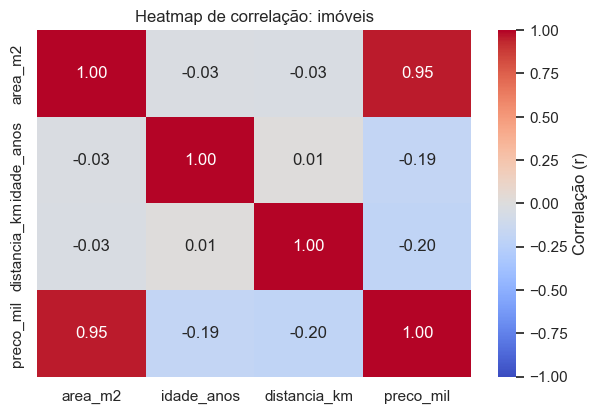

In [15]:
corr_im = df_imoveis.corr()                             # matriz de correlação (4 x 4)
sns.heatmap(corr_im, annot=True, fmt='.2f',             # escreve os valores
            cmap='coolwarm', vmin=-1, vmax=1,           # cores de -1 a 1
            cbar_kws={'label': 'Correlação (r)'})       # legenda da barra
plt.title('Heatmap de correlação: imóveis')             # título
plt.show()                                              # exibe

### Treinando a regressão múltipla

Os 7 passos, agora com 3 colunas em X.

**🔍 Linha a linha**

- `colunas = [...]`: uma lista com os nomes das variáveis. `df_imoveis[colunas]` seleciona essas 3 colunas de uma vez.
- `train_test_split`, `LinearRegression()` e `.fit` são **exatamente os mesmos** do Bloco 4.
- `modelo_imoveis.coef_`: agora é uma lista com **3 valores**, na mesma ordem de `colunas`.
- `to_string(index=False)`: imprime a tabela sem a coluna de números à esquerda.
- Os coeficientes ficam perto de 5, −3 e −8: o modelo recuperou a regra verdadeira.

In [16]:
colunas = ['area_m2', 'idade_anos', 'distancia_km']     # lista das variáveis explicativas
X = df_imoveis[colunas]                                 # X com 3 colunas
y = df_imoveis['preco_mil']                             # y = preço

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)   # treino e teste

modelo_imoveis = LinearRegression()                     # cria o modelo
modelo_imoveis.fit(X_treino, y_treino)                  # treina

tabela_coef = pd.DataFrame({                            # tabela de coeficientes
    'variavel': colunas,                                # nome de cada variável
    'coeficiente': modelo_imoveis.coef_.round(2)        # coeficiente aprendido
})
print(f'Intercepto: {modelo_imoveis.intercept_:.1f}')   # b0
print(tabela_coef.to_string(index=False))               # mostra a tabela sem o índice

Intercepto: 98.6
    variavel  coeficiente
     area_m2         5.02
  idade_anos        -2.90
distancia_km        -8.29


### 🗣️ Interpretando (ceteris paribus: "tudo o mais constante")

- **área ≈ +5:** cada m² a mais aumenta o preço em ≈ R\$ 5 mil, **mantendo idade e distância iguais**. 
- **idade ≈ −3:** cada ano a mais reduz o preço em ≈ R\$ 3 mil.
- **distância ≈ −8:** cada km a mais do centro reduz o preço em ≈ R\$ 8 mil.

### Avaliando e comparando com a regressão simples

Será que usar três variáveis melhora em relação a usar só a área?

**🔍 Linha a linha**

- Calculamos as métricas da múltipla e, em seguida, treinamos um segundo modelo que usa **só a área** para comparar.
- `X_treino[['area_m2']]`: seleciona apenas a coluna da área (colchetes duplos de novo).
- Resultado esperado: R² maior e MAE menor com 3 variáveis; a idade e a distância explicam parte do preço que a área sozinha não explica.

In [17]:
y_prev = modelo_imoveis.predict(X_teste)                # previsões da múltipla
r2_multi = r2_score(y_teste, y_prev)                    # R² da múltipla
mae_multi = mean_absolute_error(y_teste, y_prev)        # MAE da múltipla

modelo_so_area = LinearRegression()                     # outro modelo, só com a área
modelo_so_area.fit(X_treino[['area_m2']], y_treino)     # treina só com a coluna da área
y_prev_area = modelo_so_area.predict(X_teste[['area_m2']])   # previsões do modelo simples
r2_area = r2_score(y_teste, y_prev_area)                # R² do modelo simples
mae_area = mean_absolute_error(y_teste, y_prev_area)    # MAE do modelo simples

print(f'Só área      -> R² = {r2_area:.3f} | MAE = {mae_area:.1f} mil')   # resultado simples
print(f'Três variáveis -> R² = {r2_multi:.3f} | MAE = {mae_multi:.1f} mil')   # resultado múltiplo

Só área      -> R² = 0.874 | MAE = 64.8 mil
Três variáveis -> R² = 0.954 | MAE = 41.0 mil


### Gráfico: real × previsto

Se o modelo fosse perfeito, todos os pontos estariam na linha diagonal.

**🔍 Linha a linha**

- `plt.scatter(y_teste, y_prev)`: cada ponto é um imóvel; quanto mais perto da diagonal, melhor a previsão.
- `limites = [min, max]`: usamos o menor e o maior preço para desenhar a diagonal.
- `linestyle='--'`: linha tracejada.

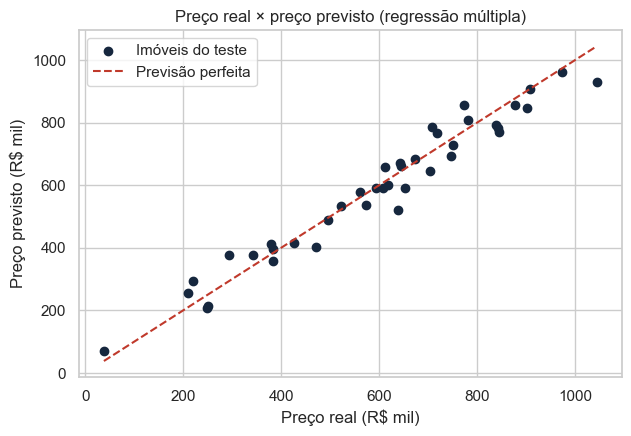

In [18]:
plt.scatter(y_teste, y_prev, color=AZUL, label='Imóveis do teste')   # x = preço real, y = preço previsto
limites = [y_teste.min(), y_teste.max()]                # menor e maior preço real
plt.plot(limites, limites, color=VERM, linestyle='--', label='Previsão perfeita')   # diagonal: previsto = real
plt.title('Preço real × preço previsto (regressão múltipla)')   # título
plt.xlabel('Preço real (R$ mil)')                       # eixo x
plt.ylabel('Preço previsto (R$ mil)')                   # eixo y
plt.legend()                                            # legenda
plt.show()                                              # exibe

# 🎯 Exercício 2 (5 min) — Um imóvel novo

**Desafio:** use o `modelo_imoveis` para prever o preço de um imóvel com **100 m²**, **10 anos** e **5 km** do centro.

> Cuidado: a tabela do novo imóvel precisa ter as colunas na mesma ordem de `colunas`.

In [19]:
# TODO: crie um DataFrame com area_m2, idade_anos e distancia_km e use modelo_imoveis.predict(...)

# 🩺 Bloco 6 — Dataset real do scikit-learn: Diabetes (20 min)

O scikit-learn traz alguns datasets prontos para estudo. O **Diabetes** reúne dados de **442 pacientes**:

| Coluna | Significado |
|---|---|
| `age`, `sex` | idade e sexo |
| `bmi` | índice de massa corporal |
| `bp` | pressão arterial média |
| `s1` a `s6` | seis exames de sangue (colesterol, glicose...) |
| **`target`** | **medida de progressão da doença após 1 ano** (quanto maior, pior) |

> Nesse dataset as variáveis já vêm **padronizadas** (média 0 e escala parecida), então os coeficientes podem ser comparados entre si: o maior (em valor absoluto) indica a variável mais influente.

**Objetivo:** prever o `target` a partir das 10 variáveis. Mesmos passos de sempre!

### Carregando o dataset

A função `load_diabetes` devolve os dados prontos, sem precisar de arquivo.

**🔍 Linha a linha**

- `from sklearn.datasets import load_diabetes`: importa a função que entrega o dataset.
- `load_diabetes(as_frame=True)`: devolve um objeto; `as_frame=True` pede os dados como tabela do pandas.
- `diabetes.frame`: a tabela completa. `df_diab.shape`: (linhas, colunas).

In [20]:
from sklearn.datasets import load_diabetes              # função que carrega o dataset Diabetes

diabetes = load_diabetes(as_frame=True)                 # carrega já em formato de tabela do pandas
df_diab = diabetes.frame                                # a tabela completa (variáveis + target)

print('Linhas e colunas:', df_diab.shape)               # (número de pacientes, número de colunas)
df_diab.head()                                          # primeiras linhas

Linhas e colunas: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


### Explorando: heatmap e correlação com o alvo

Quais variáveis mais se relacionam com a progressão da doença?

**🔍 Linha a linha**

- `plt.figure(figsize=(8, 6))`: cria uma figura maior, porque o heatmap tem 11 linhas e colunas.
- `corr_d['target']`: só a coluna do alvo na matriz (correlação de todas as variáveis com ele).
- `.drop('target')`: remove a linha do próprio alvo (que valeria 1).
- `.sort_values()`: ordena do menor para o maior.
- Leitura: `bmi` e `s5` têm as maiores correlações positivas com o alvo.

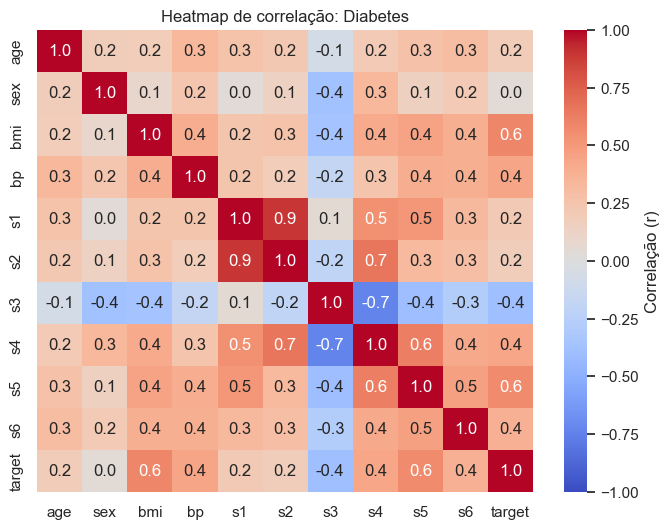

s3    -0.39
sex    0.04
s2     0.17
age    0.19
s1     0.21
s6     0.38
s4     0.43
bp     0.44
s5     0.57
bmi    0.59
Name: target, dtype: float64


In [21]:
corr_d = df_diab.corr()                                 # matriz de correlação (11 x 11)
plt.figure(figsize=(8, 6))                              # gráfico um pouco maior
sns.heatmap(corr_d, annot=True, fmt='.1f',              # valores com 1 casa para caber
            cmap='coolwarm', vmin=-1, vmax=1,           # cores de -1 a 1
            cbar_kws={'label': 'Correlação (r)'})       # legenda da barra
plt.title('Heatmap de correlação: Diabetes')            # título
plt.show()                                              # exibe

corr_alvo = corr_d['target'].drop('target').sort_values()   # correlação de cada variável com o alvo, em ordem
print(corr_alvo.round(2))                               # mostra os valores

### Treinando e avaliando

Os 7 passos, agora em um dataset real com 10 variáveis.

**🔍 Linha a linha**

- `df_diab.drop(columns='target')`: devolve a tabela **sem** a coluna alvo. Todas as demais viram X.
- O restante é idêntico aos blocos anteriores: dividir, criar, treinar, prever e avaliar.
- R² em torno de 0,45: o modelo explica menos da metade da variação; dados reais costumam ser **mais difíceis** que os sintéticos (há muito fator que não medimos).

In [22]:
X = df_diab.drop(columns='target')                      # X = todas as colunas, exceto o alvo
y = df_diab['target']                                   # y = progressão da doença

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)   # treino/teste

modelo_diab = LinearRegression()                        # cria o modelo
modelo_diab.fit(X_treino, y_treino)                     # treina
y_prev = modelo_diab.predict(X_teste)                   # prevê no teste

print(f'R²   = {r2_score(y_teste, y_prev):.3f}')                          # qualidade geral
print(f'MAE  = {mean_absolute_error(y_teste, y_prev):.1f}')               # erro médio
print(f'RMSE = {np.sqrt(mean_squared_error(y_teste, y_prev)):.1f}')       # raiz do erro quadrático

R²   = 0.453
MAE  = 42.8
RMSE = 53.9


### Gráficos: coeficientes e real × previsto

Dois gráficos: quais variáveis mais pesam, e como as previsões se comportam.

**🔍 Linha a linha**

- `plt.subplots(1, 2)`: cria uma figura com 2 gráficos; `eixos[0]` é o da esquerda e `eixos[1]` o da direita.
- `pd.Series(modelo_diab.coef_, index=X.columns)`: junta os coeficientes aos nomes das variáveis.
- `[VERM if c < 0 else AZUL for c in coef]`: escolhe uma cor para cada barra (vermelho para coeficiente negativo, azul para positivo).
- `eixos[0].barh(...)`: barras **h**orizontais. Quando usamos `eixos[i]`, os métodos de título ficam `set_title`, `set_xlabel`, `set_ylabel`.
- `plt.tight_layout()`: ajusta os espaços para nada ficar sobreposto.

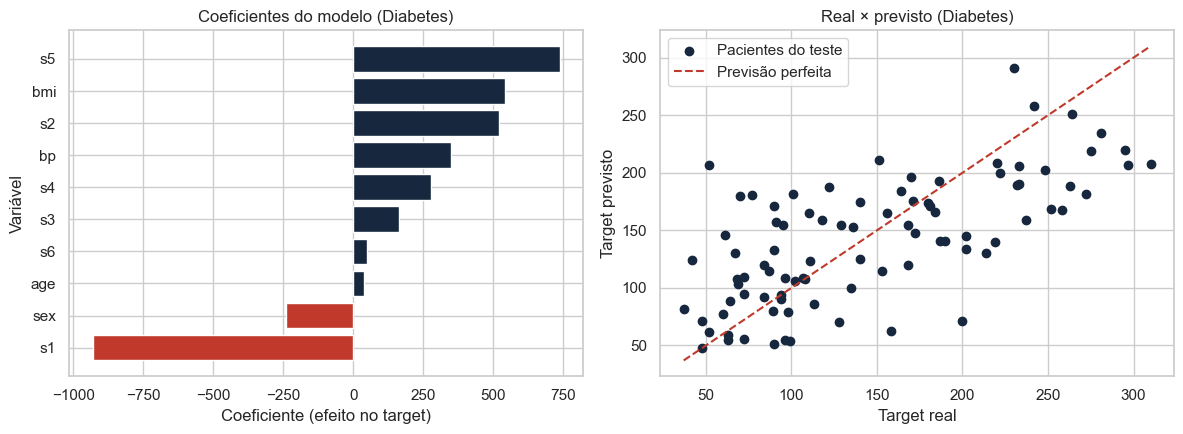

In [23]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))       # 1 linha, 2 gráficos lado a lado

coef = pd.Series(modelo_diab.coef_, index=X.columns).sort_values()   # coeficientes com os nomes das variáveis
cores = [VERM if c < 0 else AZUL for c in coef]         # vermelho se negativo, azul se positivo
eixos[0].barh(coef.index, coef.values, color=cores)     # barras horizontais
eixos[0].set_title('Coeficientes do modelo (Diabetes)') # título do 1º gráfico
eixos[0].set_xlabel('Coeficiente (efeito no target)')   # eixo x
eixos[0].set_ylabel('Variável')                         # eixo y

eixos[1].scatter(y_teste, y_prev, color=AZUL, label='Pacientes do teste')   # real x previsto
lim = [y_teste.min(), y_teste.max()]                    # limites da diagonal
eixos[1].plot(lim, lim, color=VERM, linestyle='--', label='Previsão perfeita')   # diagonal
eixos[1].set_title('Real × previsto (Diabetes)')        # título do 2º gráfico
eixos[1].set_xlabel('Target real')                      # eixo x
eixos[1].set_ylabel('Target previsto')                  # eixo y
eixos[1].legend()                                       # legenda
plt.tight_layout()                                      # evita sobreposição
plt.show()                                              # exibe

👀 **Leitura:** `s5` e `bmi` têm coeficientes positivos grandes (mais IMC, pior progressão). Já `s1` e `s2` aparecem com coeficientes grandes de **sinais opostos**: no heatmap elas têm r ≈ 0,9 entre si, ou seja, são quase a mesma informação e os coeficientes "brigam" um com o outro. **Cuidado:** com variáveis muito correlacionadas entre si, não interprete os coeficientes isoladamente.

# 🎯 Exercício 3 (5 min) — Qual variável mais se relaciona com o alvo?

**Desafio:** usando `corr_d`, descubra qual variável tem a **maior correlação positiva** com `target` e qual o valor de r.

In [24]:
# TODO: pegue corr_d['target'], retire o próprio 'target' e use .idxmax() e .max()

# 🎯 Exercício 4 (10 min) — Regressão simples com IMC

**Desafio:** treine uma **regressão simples** que preveja `target` usando **só a variável `bmi`** (mesma divisão treino/teste de sempre: `test_size=0.2`, `random_state=42`). Mostre o **R²** no teste e compare com o do modelo completo.

In [25]:
# TODO: X = df_diab[['bmi']]; y = df_diab['target']; divida, treine, preveja e calcule o R²

# 🏁 Bloco 7 — Fechamento (10 min)

## Resumo da aula

| Conceito | Em uma frase |
|---|---|
| **Correlação (r)** | força da relação **em linha reta**, de −1 a +1 |
| **Heatmap** | mapa de cores da matriz de correlação |
| **Regressão linear** | reta (ou combinação linear) que descreve e **prevê** |
| **Coeficiente** | quanto o alvo muda a cada +1 na variável (mantendo as demais constantes) |
| **Treino × teste** | estudar com uma parte dos dados e ser avaliado na outra |
| **R², MAE, RMSE** | qualidade do modelo (R² alto, erros baixos) |

## Receita dos 7 passos (vale para qualquer regressão)

```python
X = df[colunas]                                   # 1. separar X e y
y = df['alvo']
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)   # 2. dividir
modelo = LinearRegression()                       # 3. criar
modelo.fit(X_treino, y_treino)                    # 4. treinar
print(modelo.intercept_, modelo.coef_)            # 5. coeficientes
y_prev = modelo.predict(X_teste)                  # 6. prever
print(r2_score(y_teste, y_prev))                  # 7. avaliar
```

## 📝 Tarefa para casa
Escolha uma coluna do `df_imoveis` ou do `df_diab`, descubra pelo heatmap qual é a variável mais correlacionada com o alvo, treine uma regressão simples com ela e **escreva 3 linhas** interpretando o coeficiente e o R².

# ✅ Gabarito dos exercícios

Respostas de todos os exercícios deste notebook. **Tente resolver antes de olhar!**

> As soluções abaixo são texto (não executam): copie o código para uma célula se quiser rodar.

## 🎯 Exercício 1 (5 min) — Prever

**Resposta (saída esperada):**

```text
Nota prevista: 77.4
```

**Código da solução:**

```python
aluno8 = pd.DataFrame({'horas_estudo': [8]})            # novo aluno com 8 horas
print(f'Nota prevista: {modelo_simples.predict(aluno8)[0]:.1f}')   # previsão
```

## 🎯 Exercício 2 (5 min) — Um imóvel novo

**Resposta (saída esperada):**

```text
Preço previsto: R$ 530 mil
```

**Código da solução:**

```python
novo_imovel = pd.DataFrame({'area_m2': [100], 'idade_anos': [10], 'distancia_km': [5]})   # novo imóvel
print(f'Preço previsto: R$ {modelo_imoveis.predict(novo_imovel)[0]:.0f} mil')   # previsão
```

## 🎯 Exercício 3 (5 min) — Qual variável mais se relaciona com o alvo?

**Resposta (saída esperada):**

```text
Variável: bmi | r = 0.59
```

**Código da solução:**

```python
corr_alvo2 = corr_d['target'].drop('target')            # correlações com o alvo (sem o próprio alvo)
print('Variável:', corr_alvo2.idxmax(), '| r =', round(corr_alvo2.max(), 2))   # nome e valor do maior r
```

## 🎯 Exercício 4 (10 min) — Regressão simples com IMC

**Resposta (saída esperada):**

```text
R² só com bmi: 0.233 | R² com as 10 variáveis: 0.453
```

**Código da solução:**

```python
X_bmi = df_diab[['bmi']]                                # só a coluna bmi
y_all = df_diab['target']                               # alvo
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X_bmi, y_all, test_size=0.2, random_state=42)   # divide
modelo_bmi = LinearRegression().fit(Xb_tr, yb_tr)       # cria e treina em uma linha
r2_bmi = r2_score(yb_te, modelo_bmi.predict(Xb_te))     # R² do modelo simples
r2_completo = r2_score(y_teste, modelo_diab.predict(X_teste))   # R² do modelo com 10 variáveis
print(f'R² só com bmi: {r2_bmi:.3f} | R² com as 10 variáveis: {r2_completo:.3f}')   # comparação
```